In [3]:
"""
OPTIMIZACIÓN EXPERIMENTAL DEL MODELO PREDICTIVO DE LPIPS
========================================================

Objetivo:
Optimizar el modelo base mediante búsqueda experimental de:
- Arquitectura MLP.
- Tasa de aprendizaje de Adam.
- Tamaño del lote (batch_size).
- Dropout.
- Activación de salida.

Criterio principal: menor MAE en validación.
El conjunto de prueba se evalúa una sola vez, al final.

Archivos requeridos:
csv/X_train.csv, csv/X_val.csv, csv/X_test.csv
csv/y_train.csv, csv/y_val.csv, csv/y_test.csv
"""
 

import random
import itertools
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import matplotlib.pyplot as plt
 

In [4]:
# ============================================================
# 0. CONFIGURACIÓN
# ============================================================

SEMILLA = 42
EPOCAS_MAXIMAS = 200
PACIENCIA = 15

N_EXPERIMENTOS = 30  # Aumentar si se desea explorar más configuraciones

CARPETA_CSV = Path("csv")
CARPETA_RESULTADOS = Path("resultados_optimizacion")

CARPETA_CSV.mkdir(parents=True, exist_ok=True)
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)

tf.keras.utils.set_random_seed(SEMILLA)
np.random.seed(SEMILLA)
random.seed(SEMILLA)

In [5]:
# ============================================================
# 1. CARGA DE DATOS
# ============================================================

X_train = pd.read_csv(CARPETA_CSV / "X_train.csv")
X_val = pd.read_csv(CARPETA_CSV / "X_val.csv")
X_test = pd.read_csv(CARPETA_CSV / "X_test.csv")

y_train = pd.read_csv(CARPETA_CSV / "y_train.csv").squeeze("columns")
y_val = pd.read_csv(CARPETA_CSV / "y_val.csv").squeeze("columns")
y_test = pd.read_csv(CARPETA_CSV / "y_test.csv").squeeze("columns")

# Convertir las entradas a arreglos numéricos compatibles con TensorFlow.
X_train = X_train.astype(np.float32)
X_val = X_val.astype(np.float32)
X_test = X_test.astype(np.float32)

y_train = np.asarray(y_train, dtype=np.float32).reshape(-1)
y_val = np.asarray(y_val, dtype=np.float32).reshape(-1)
y_test = np.asarray(y_test, dtype=np.float32).reshape(-1)

n_features = X_train.shape[1]

print("=" * 70)
print("OPTIMIZACIÓN DEL MODELO PREDICTIVO DE LPIPS")
print("=" * 70)
print(f"Características de entrada: {n_features}")
print(f"Entrenamiento: {len(X_train)}")
print(f"Validación:    {len(X_val)}")
print(f"Prueba:        {len(X_test)}")

OPTIMIZACIÓN DEL MODELO PREDICTIVO DE LPIPS
Características de entrada: 32
Entrenamiento: 20990
Validación:    4498
Prueba:        4499


In [6]:
# ============================================================
# 2. ESPACIO DE BÚSQUEDA DE HIPERPARÁMETROS
# ============================================================

# Se conserva MAE como función de pérdida porque fue la
# seleccionada en la etapa experimental anterior.

arquitecturas = [
    (64, 32),             # Modelo A: línea base
    (128, 64, 32),        # Modelo B: arquitectura más profunda
    (128, 64),            # Arquitectura alternativa
    (256, 128, 64)        # Arquitectura de mayor capacidad
]

tasas_aprendizaje = [0.001, 0.0005, 0.0001]
tamanos_lote = [32, 64, 128]
dropouts = [0.0, 0.1, 0.2, 0.3]
activaciones_salida = ["linear", "softplus"]

espacio_busqueda = list(itertools.product(
    arquitecturas,
    tasas_aprendizaje,
    tamanos_lote,
    dropouts,
    activaciones_salida
))

# Selección reproducible de 30 combinaciones para evitar ejecutar
# todas las combinaciones posibles en una primera búsqueda.
generador = random.Random(SEMILLA)
n_elegidos = min(N_EXPERIMENTOS, len(espacio_busqueda))
configuraciones = generador.sample(espacio_busqueda, n_elegidos)

# Incluir obligatoriamente la configuración base:
# Modelo A, Adam 0.001, lote 64, Dropout 0.2 y salida lineal.
config_base = ((64, 32), 0.001, 64, 0.2, "linear")

if config_base not in configuraciones:
    configuraciones[-1] = config_base

print(f"\nConfiguraciones que se entrenarán: {len(configuraciones)}")


Configuraciones que se entrenarán: 30


In [7]:
# ============================================================
# 3. CONSTRUCCIÓN DEL MODELO
# ============================================================

def construir_mlp(
    capas_ocultas,
    n_features,
    dropout_rate,
    activacion_salida
):
    modelo = keras.Sequential()

    modelo.add(layers.Input(shape=(n_features,)))

    for neuronas in capas_ocultas:
        modelo.add(
            layers.Dense(neuronas, activation="relu")
        )

        if dropout_rate > 0:
            modelo.add(layers.Dropout(dropout_rate))

    modelo.add(
        layers.Dense(1, activation=activacion_salida)
    )

    return modelo

In [8]:
# ============================================================
# 4. ENTRENAMIENTO Y EVALUACIÓN SOBRE VALIDACIÓN
# ============================================================

def entrenar_configuracion(configuracion, numero):
    arquitectura, lr, batch_size, dropout, activacion = configuracion

    # Reiniciar la semilla hace más reproducible cada experimento.
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEMILLA)

    modelo = construir_mlp(
        capas_ocultas=arquitectura,
        n_features=n_features,
        dropout_rate=dropout,
        activacion_salida=activacion
    )

    modelo.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=lr
        ),
        loss="mae",
        metrics=["mae"]
    )

    parada_temprana = keras.callbacks.EarlyStopping(
        monitor="val_mae",
        mode="min",
        patience=PACIENCIA,
        restore_best_weights=True
    )

    historial = modelo.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCAS_MAXIMAS,
        batch_size=batch_size,
        callbacks=[parada_temprana],
        verbose=0
    )

    predicciones = modelo.predict(
        X_val,
        verbose=0
    ).reshape(-1)

    mae = mean_absolute_error(y_val, predicciones)
    rmse = np.sqrt(mean_squared_error(y_val, predicciones))
    r2 = r2_score(y_val, predicciones)

    negativas = predicciones < 0
    n_negativas = int(negativas.sum())

    resultado = {
        "experimento": numero,
        "arquitectura": "-".join(map(str, arquitectura)),
        "learning_rate": lr,
        "batch_size": batch_size,
        "dropout": dropout,
        "activacion_salida": activacion,
        "funcion_perdida": "MAE",
        "epocas_entrenadas": len(historial.history["loss"]),
        "val_MAE": mae,
        "val_RMSE": rmse,
        "val_R2": r2,
        "pred_negativas_n": n_negativas,
        "pred_negativas_pct": 100 * n_negativas / len(predicciones)
    }

    return modelo, resultado, historial.history


In [9]:
# ============================================================
# 5. BÚSQUEDA EXPERIMENTAL
# ============================================================

resultados = []
mejor_mae = float("inf")
mejor_modelo = None
mejor_resultado = None
mejor_historial = None

for i, configuracion in enumerate(configuraciones, start=1):

    arquitectura, lr, batch, dropout, activacion = configuracion

    print(
        f"\nExperimento {i}/{len(configuraciones)} | "
        f"Arquitectura={arquitectura} | "
        f"LR={lr} | Batch={batch} | "
        f"Dropout={dropout} | Salida={activacion}"
    )

    modelo, resultado, historial = entrenar_configuracion(
        configuracion,
        i
    )

    resultados.append(resultado)

    print(
        f"MAE={resultado['val_MAE']:.6f} | "
        f"RMSE={resultado['val_RMSE']:.6f} | "
        f"R2={resultado['val_R2']:.5f} | "
        f"Negativas={resultado['pred_negativas_pct']:.2f}%"
    )

    if resultado["val_MAE"] < mejor_mae:
        mejor_mae = resultado["val_MAE"]
        mejor_modelo = modelo
        mejor_resultado = resultado.copy()
        mejor_historial = historial

        # Guardar inmediatamente el mejor modelo encontrado.
        mejor_modelo.save(
            CARPETA_RESULTADOS / "mejor_modelo_temporal.keras"
        )

    del modelo



Experimento 1/30 | Arquitectura=(64, 32) | LR=0.0001 | Batch=64 | Dropout=0.0 | Salida=softplus

MAE=0.011171 | RMSE=0.022552 | R2=0.93615 | Negativas=0.00%

Experimento 2/30 | Arquitectura=(64, 32) | LR=0.001 | Batch=64 | Dropout=0.2 | Salida=linear
MAE=0.010593 | RMSE=0.021363 | R2=0.94271 | Negativas=0.00%

Experimento 3/30 | Arquitectura=(128, 64, 32) | LR=0.0001 | Batch=128 | Dropout=0.2 | Salida=linear
MAE=0.012833 | RMSE=0.027395 | R2=0.90578 | Negativas=0.13%

Experimento 4/30 | Arquitectura=(128, 64, 32) | LR=0.0001 | Batch=32 | Dropout=0.2 | Salida=softplus
MAE=0.010266 | RMSE=0.020575 | R2=0.94685 | Negativas=0.00%

Experimento 5/30 | Arquitectura=(128, 64, 32) | LR=0.0005 | Batch=128 | Dropout=0.1 | Salida=linear
MAE=0.011034 | RMSE=0.022670 | R2=0.93548 | Negativas=0.00%

Experimento 6/30 | Arquitectura=(64, 32) | LR=0.0001 | Batch=128 | Dropout=0.3 | Salida=softplus
MAE=0.011850 | RMSE=0.023519 | R2=0.93056 | Negativas=0.00%

Experimento 7/30 | Arquitectura=(64, 32) | LR

In [10]:
# ============================================================
# 6. COMPARACIÓN Y GUARDADO DE RESULTADOS
# ============================================================

tabla_resultados = (
    pd.DataFrame(resultados)
    .sort_values("val_MAE")
    .reset_index(drop=True)
)

ruta_resultados = CARPETA_RESULTADOS / "comparacion_optimizacion.csv"
tabla_resultados.to_csv(ruta_resultados, index=False)

print("\n" + "=" * 90)
print("RESULTADOS DE OPTIMIZACIÓN ORDENADOS POR MAE DE VALIDACIÓN")
print("=" * 90)
print(tabla_resultados.to_string(index=False))

print("\nMejor configuración según validación:")
for clave, valor in mejor_resultado.items():
    print(f"{clave}: {valor}")


RESULTADOS DE OPTIMIZACIÓN ORDENADOS POR MAE DE VALIDACIÓN
 experimento arquitectura  learning_rate  batch_size  dropout activacion_salida funcion_perdida  epocas_entrenadas  val_MAE  val_RMSE   val_R2  pred_negativas_n  pred_negativas_pct
          29       128-64         0.0005          32      0.2            linear             MAE                 86 0.010162  0.020488 0.947306               663           14.739884
          30       128-64         0.0001          32      0.1            linear             MAE                137 0.010203  0.021153 0.943827               252            5.602490
           4    128-64-32         0.0001          32      0.2          softplus             MAE                194 0.010266  0.020575 0.946855                 0            0.000000
          19    128-64-32         0.0005          32      0.2          softplus             MAE                 78 0.010411  0.021299 0.943051                 0            0.000000
          15    128-64-32         0

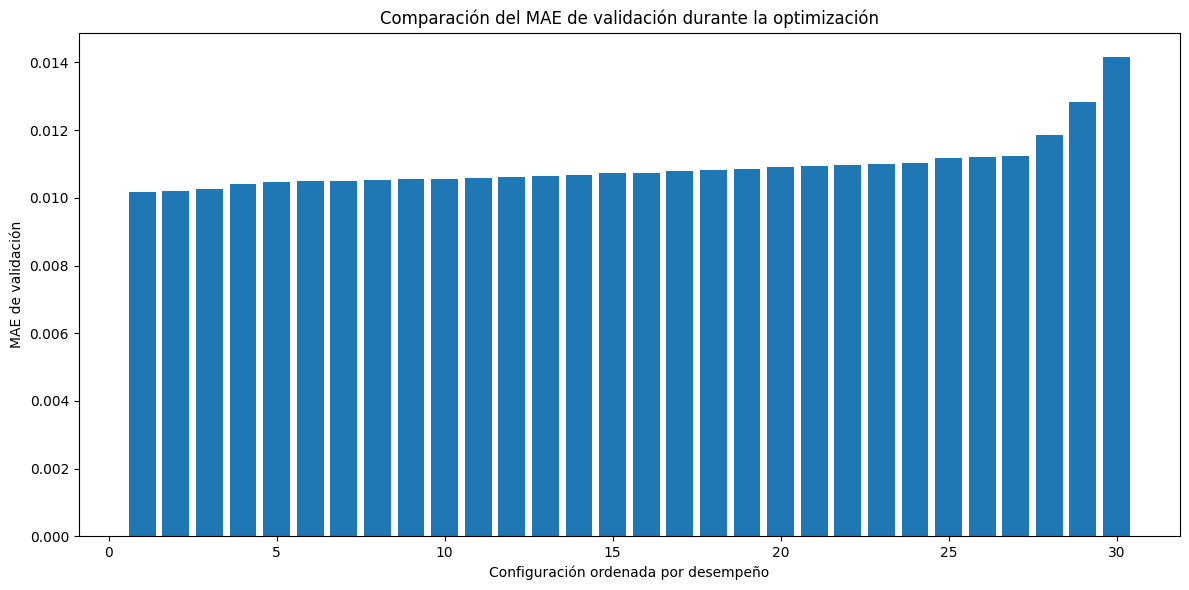

In [11]:
# ============================================================
# 7. GRÁFICA DE COMPARACIÓN DE EXPERIMENTOS
# ============================================================

plt.figure(figsize=(12, 6))

plt.bar(
    range(1, len(tabla_resultados) + 1),
    tabla_resultados["val_MAE"]
)

plt.xlabel("Configuración ordenada por desempeño")
plt.ylabel("MAE de validación")
plt.title("Comparación del MAE de validación durante la optimización")
plt.tight_layout()

plt.savefig(
    CARPETA_RESULTADOS / "comparacion_mae_validacion.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


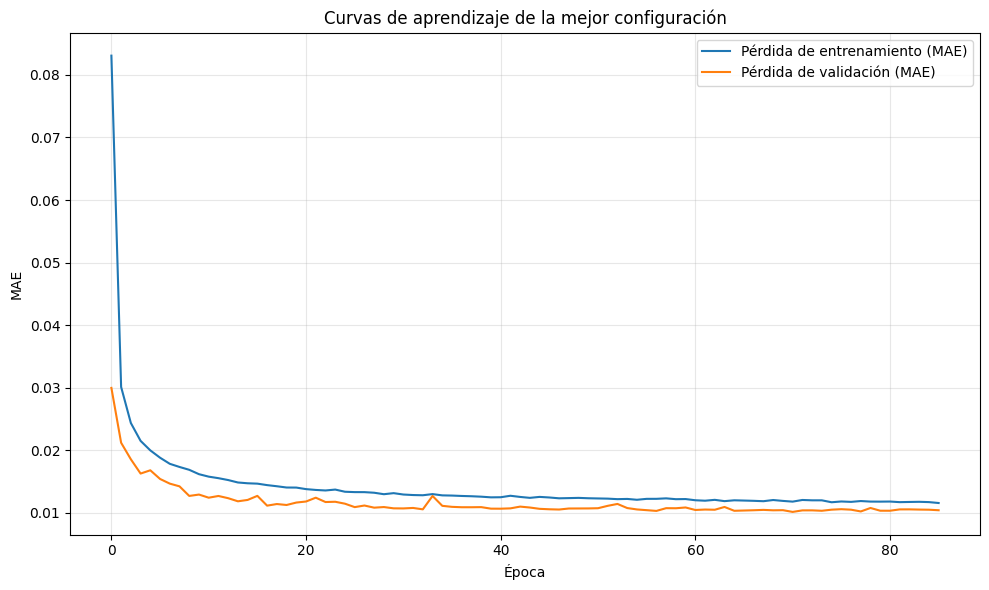

In [13]:
# ============================================================
# 8. CURVAS DE APRENDIZAJE DE LA MEJOR CONFIGURACIÓN
# ============================================================

plt.figure(figsize=(10, 6))

plt.plot(
    mejor_historial["loss"],
    label="Pérdida de entrenamiento (MAE)"
)
plt.plot(
    mejor_historial["val_loss"],
    label="Pérdida de validación (MAE)"
)

plt.xlabel("Época")
plt.ylabel("MAE")
plt.title("Curvas de aprendizaje de la mejor configuración")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    CARPETA_RESULTADOS / "curvas_mejor_modelo.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [14]:
# ============================================================
# 9. EVALUACIÓN FINAL ÚNICA SOBRE TEST
# ============================================================

# Hasta este punto, el conjunto de prueba no se ha utilizado
# para seleccionar ni ajustar las configuraciones.

mejor_modelo.save(
    CARPETA_RESULTADOS / "modelo_lpips_optimizado.keras"
)

y_pred_test = mejor_modelo.predict(
    X_test,
    verbose=0
).reshape(-1)

mae_test = mean_absolute_error(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
r2_test = r2_score(y_test, y_pred_test)

n_neg_test = int((y_pred_test < 0).sum())

print("\n" + "=" * 70)
print("EVALUACIÓN FINAL DEL MODELO OPTIMIZADO")
print("=" * 70)
print(f"Test MAE:  {mae_test:.6f}")
print(f"Test RMSE: {rmse_test:.6f}")
print(f"Test R2:   {r2_test:.5f}")
print(
    f"Predicciones negativas: {n_neg_test} "
    f"({100 * n_neg_test / len(y_pred_test):.2f}%)"
)

# Guardar métricas finales.
metricas_test = pd.DataFrame([{
    "arquitectura": mejor_resultado["arquitectura"],
    "learning_rate": mejor_resultado["learning_rate"],
    "batch_size": mejor_resultado["batch_size"],
    "dropout": mejor_resultado["dropout"],
    "activacion_salida": mejor_resultado["activacion_salida"],
    "test_MAE": mae_test,
    "test_RMSE": rmse_test,
    "test_R2": r2_test,
    "test_pred_negativas_n": n_neg_test,
    "test_pred_negativas_pct": 100 * n_neg_test / len(y_pred_test)
}])

metricas_test.to_csv(
    CARPETA_RESULTADOS / "metricas_finales_test.csv",
    index=False
)

print("\nArchivos guardados en:", CARPETA_RESULTADOS.resolve())
print("- comparacion_optimizacion.csv")
print("- comparacion_mae_validacion.png")
print("- curvas_mejor_modelo.png")
print("- modelo_lpips_optimizado.keras")
print("- metricas_finales_test.csv")


EVALUACIÓN FINAL DEL MODELO OPTIMIZADO
Test MAE:  0.010429
Test RMSE: 0.020910
Test R2:   0.94728
Predicciones negativas: 679 (15.09%)

Archivos guardados en: D:\TrabajoGrado\Codigos\Funciones_Matematicas\resultados_optimizacion
- comparacion_optimizacion.csv
- comparacion_mae_validacion.png
- curvas_mejor_modelo.png
- modelo_lpips_optimizado.keras
- metricas_finales_test.csv
